
# Part 2: Classification and Model Improvement

## Breast Cancer Classification Using Machine Learning

### Introduction

This research endeavors to assess the deployment of supervised machine learning techniques for the purpose of categorizing breast cancer diagnostic presentations into malignant or benign classifications.

Utilizing the Wisconsin Diagnostic Breast Cancer dataset, this study will execute exploratory data analysis, perform data preprocessing and curation, conduct feature selection and engineering, construct a Logistic Regression classification model, evaluate model efficacy through appropriate metrics, and implement refinements to enhance predictive accuracy where indicated.

The research will prioritize the examination of pertinent classification performance indicators, with emphasis on recall metrics for malignant case detection, while recognizing that the developed model represents an educational framework rather than a validated clinical diagnostic system.

### Analysis workflow
1. Load and describe the dataset.
2. Validate data quality and explore patterns visually.
3. Split data into stratified training and test sets.
4. Build a baseline Logistic Regression pipeline with scaling and Recursive Feature Elimination (RFE).
5. Tune feature count, regularisation strength and class weighting using five-fold cross-validation on training data only.
6. Evaluate both models on the same untouched test set.
7. Interpret false negatives and limitations, and make evidence-based recommendations.

## 1. Import libraries

Pandas and NumPy support data manipulation; Matplotlib and Seaborn support visualisation. Scikit-learn provides the dataset, data splitting, preprocessing, feature selection, modelling, cross-validation and evaluation metrics.

In [1]:

# Import libraries for data handling and numerical calculations
import pandas as pd
import numpy as np

# Import libraries for data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Import the breast cancer dataset
from sklearn.datasets import load_breast_cancer

# Import tools for splitting data and preparing features
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Import feature selection and classification tools
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# Import classification evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Make visualisations easier to read
sns.set_theme(style="whitegrid")

# Set a consistent random seed for reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

# Load the Wisconsin Diagnostic Breast Cancer dataset
cancer_data = load_breast_cancer(as_frame=True)

# Create a DataFrame containing the 30 predictive features
X = cancer_data.data.copy()

# Create the original diagnosis target
original_target = cancer_data.target

# Convert the target so that malignant = 1 and benign = 0
y = (original_target == 0).astype(int)

# Create a combined DataFrame for inspection and exploratory analysis
df = X.copy()
df["diagnosis"] = y.map({1: "Malignant", 0: "Benign"})

# Display the first five observations
display(df.head())

# Display the size of the dataset
print("Number of rows:", df.shape[0])
print("Number of columns, including diagnosis:", df.shape[1])
print("Number of predictive features:", X.shape[1])


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant


Number of rows: 569
Number of columns, including diagnosis: 31
Number of predictive features: 30


## 3. Dataset suitability and quality checks

The checks below inspect data types, missing values, duplicate rows, non-finite values, zero-variance features and target balance.

In [3]:

# Inspect the data types and non-null counts
print("Dataset information:")
df.info()

# Review summary statistics for the numerical features
print("\nDescriptive statistics:")
display(X.describe().T)

# Check for missing values
print("\nMissing values per column:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

# Check for duplicate observations
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check the number of cases in each diagnosis class
print("\nDiagnosis distribution:")
display(df["diagnosis"].value_counts())

# Show the proportion of each diagnosis class
print("\nDiagnosis proportions:")
display(df["diagnosis"].value_counts(normalize=True).mul(100).round(2))


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Missing values per column:


mean radius               0
mean texture              0
mean perimeter            0
mean area                 0
mean smoothness           0
mean compactness          0
mean concavity            0
mean concave points       0
mean symmetry             0
mean fractal dimension    0
dtype: int64


Number of duplicate rows: 0

Diagnosis distribution:


diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


Diagnosis proportions:


diagnosis
Benign       62.74
Malignant    37.26
Name: proportion, dtype: float64

In [4]:

# Count the number of cases in each diagnosis category
diagnosis_counts = df["diagnosis"].value_counts()

# Display the counts
print("Number of cases by diagnosis:")
display(diagnosis_counts)

# Calculate the percentage of each diagnosis category
diagnosis_percentages = df["diagnosis"].value_counts(normalize=True) * 100

print("\nPercentage of cases by diagnosis:")
display(diagnosis_percentages.round(2))


Number of cases by diagnosis:


diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


Percentage of cases by diagnosis:


diagnosis
Benign       62.74
Malignant    37.26
Name: proportion, dtype: float64

## 4. Exploratory Data Analysis (EDA)

EDA helps establish the distribution of the target, the range of predictor values and possible relationships between features and diagnosis.

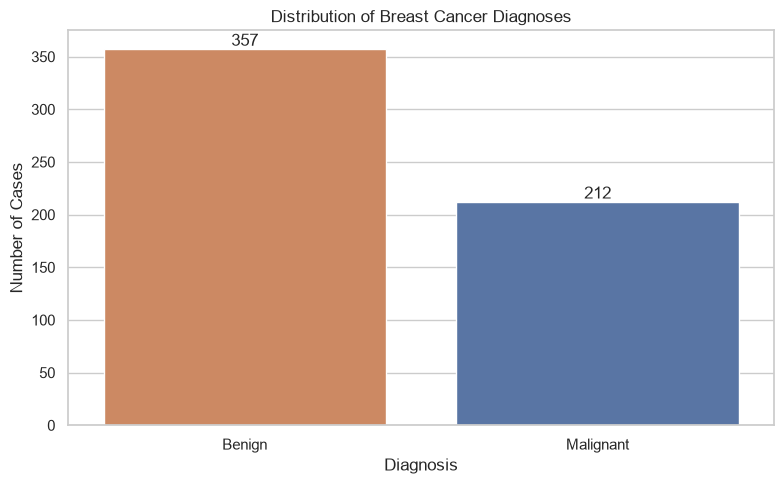

In [5]:

# Create a bar chart showing the number of cases in each diagnosis category
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="diagnosis",
    hue="diagnosis",
    order=["Benign", "Malignant"],
    legend=False
)

# Add a descriptive title and axis labels
plt.title("Distribution of Breast Cancer Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")

# Display the values above the bars
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height())}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


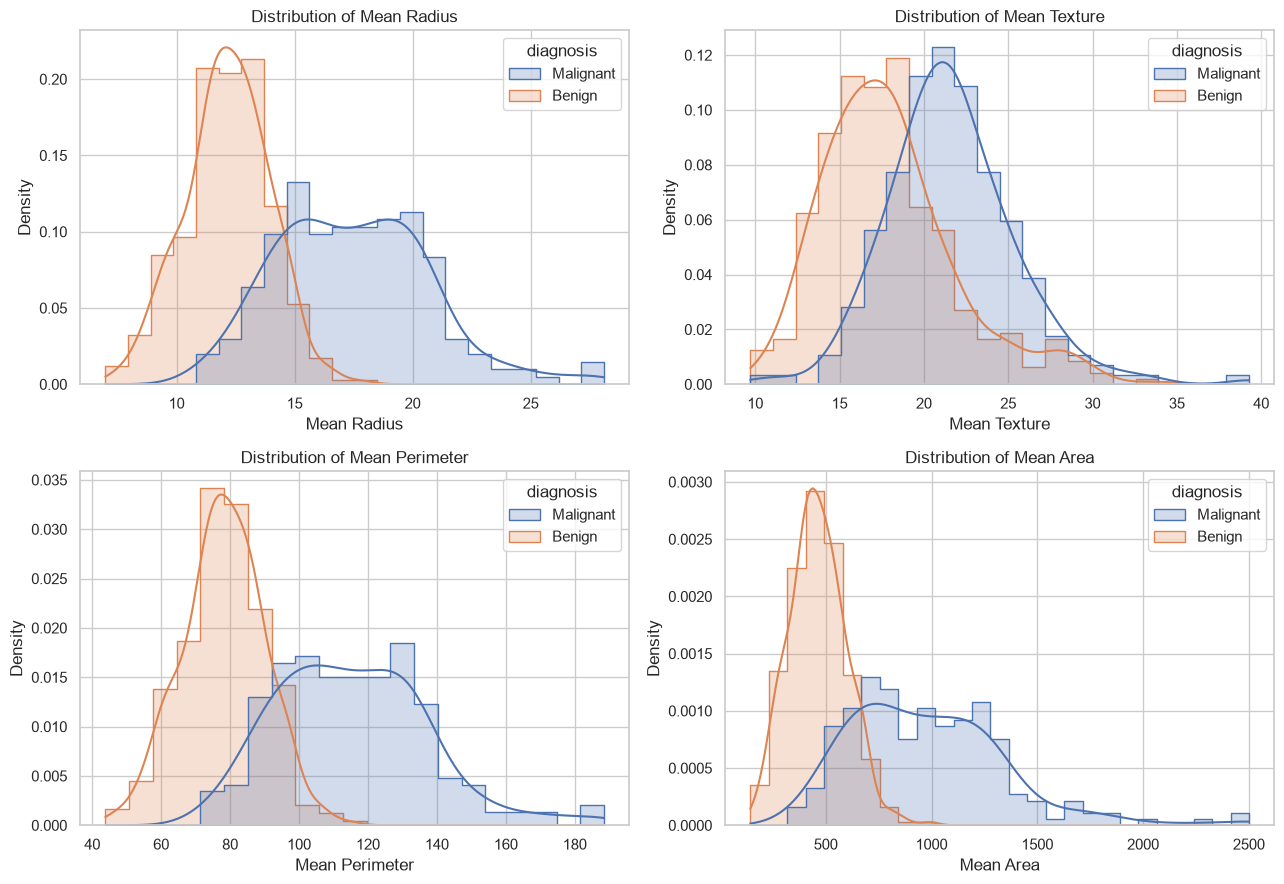

In [7]:

# Select features using the column names in the scikit-learn dataset
features_to_plot = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area"
]

# Create four graphs to compare benign and malignant cases
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, feature in zip(axes, features_to_plot):
    sns.histplot(
        data=df,
        x=feature,
        hue="diagnosis",
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature.title()}")
    ax.set_xlabel(feature.title())
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()


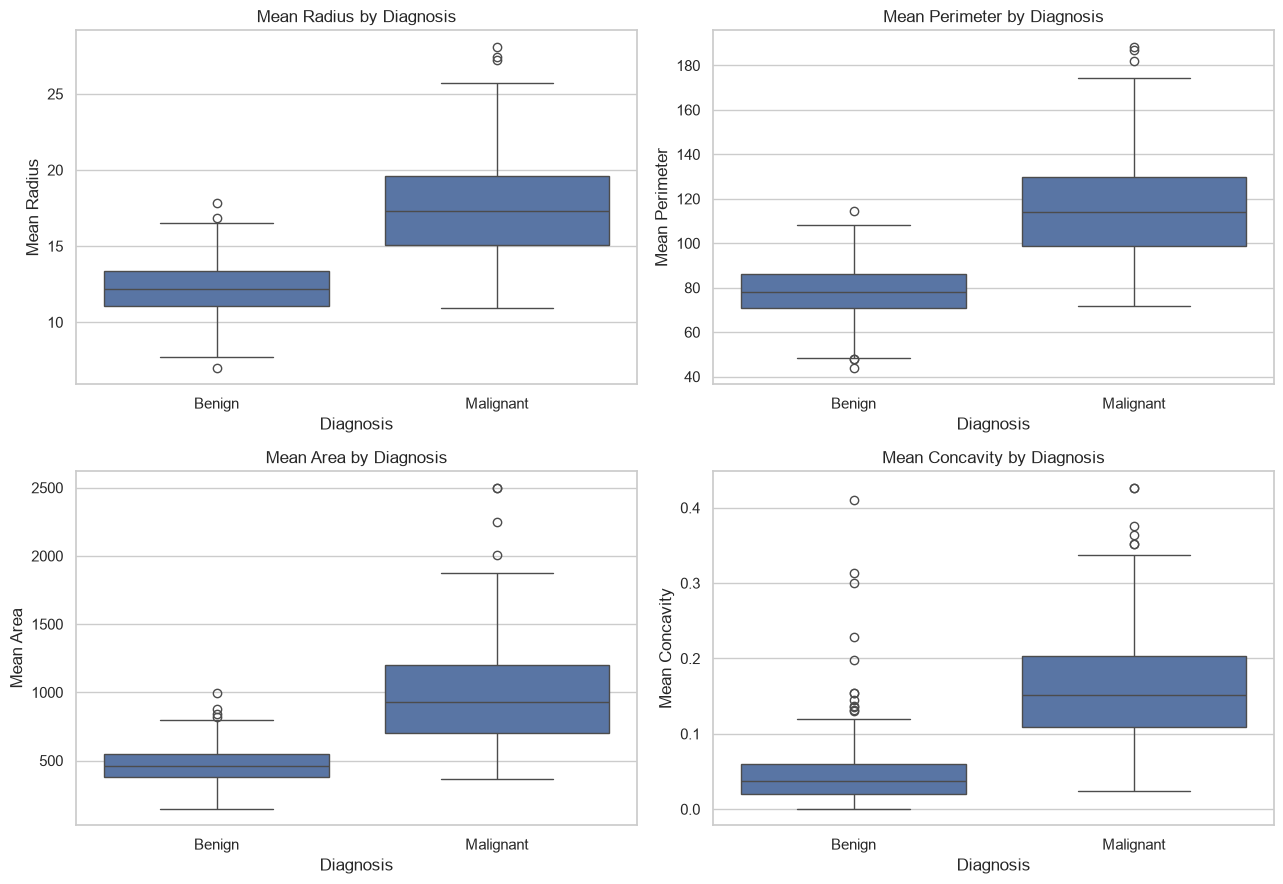

In [8]:

# Compare selected feature values for benign and malignant cases
features_to_compare = [
    "mean radius",
    "mean perimeter",
    "mean area",
    "mean concavity"
]

# Create boxplots to show differences and potential outliers
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, feature in zip(axes, features_to_compare):
    sns.boxplot(
        data=df,
        x="diagnosis",
        y=feature,
        order=["Benign", "Malignant"],
        ax=ax
    )

    ax.set_title(f"{feature.title()} by Diagnosis")
    ax.set_xlabel("Diagnosis")
    ax.set_ylabel(feature.title())

plt.tight_layout()
plt.show()


Ten strongest absolute feature correlations:


,,Pearson correlation
mean radius,mean perimeter,0.997855
worst radius,worst perimeter,0.993708
mean radius,mean area,0.987357
mean perimeter,mean area,0.986507
worst radius,worst area,0.984015
worst perimeter,worst area,0.977578
radius error,perimeter error,0.972794
mean perimeter,worst perimeter,0.970387
mean radius,worst radius,0.969539
mean perimeter,worst radius,0.969476


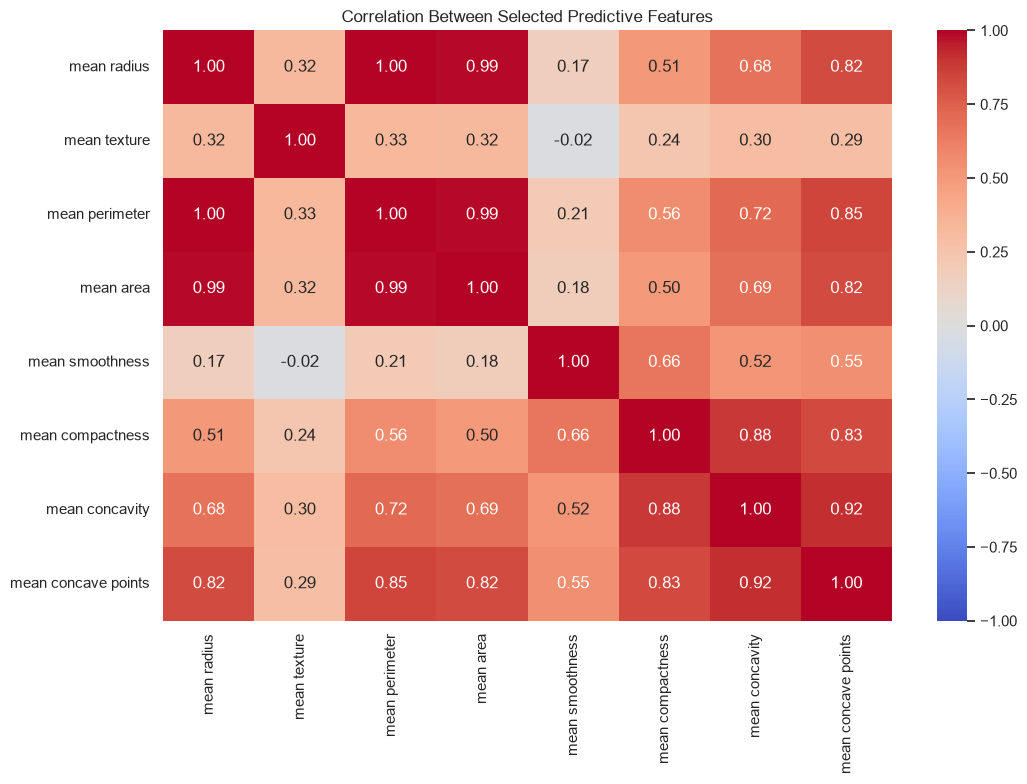

In [9]:

# Calculate the Pearson correlation matrix for the numerical features
correlation_matrix = X.corr()

# Display the strongest positive and negative correlations
# Exclude the diagonal self-correlations
correlation_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack()

print("Ten strongest absolute feature correlations:")
display(
    correlation_pairs.loc[
        correlation_pairs.abs().sort_values(ascending=False).head(10).index
    ].to_frame(name="Pearson correlation")
)

# Visualise correlations among a smaller set of relevant features
selected_correlation_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean compactness",
    "mean concavity",
    "mean concave points"
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    X[selected_correlation_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Selected Predictive Features")
plt.tight_layout()
plt.show()


In [10]:

# Confirm the dataset dimensions
print("Dataset dimensions:", df.shape)

# Count missing values
print("Total missing values:", df.isnull().sum().sum())

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check whether all predictor values are finite numbers
print("All predictor values are finite:", np.isfinite(X.to_numpy()).all())

# Summarise the diagnosis classes
print("\nDiagnosis summary:")
display(
    df["diagnosis"].value_counts().rename_axis("Diagnosis").to_frame("Count")
)

# Review descriptive statistics for possible unusual values
print("\nFeature ranges:")
display(X.describe().T[["min", "mean", "max"]])


Dataset dimensions: (569, 31)
Total missing values: 0
Duplicate rows: 0
All predictor values are finite: True

Diagnosis summary:


,Count
Diagnosis,
Benign,357
Malignant,212



Feature ranges:


,min,mean,max
mean radius,6.981000,14.127292,28.11000
mean texture,9.710000,19.289649,39.28000
mean perimeter,43.790000,91.969033,188.50000
mean area,143.500000,654.889104,2501.00000
mean smoothness,0.052630,0.096360,0.16340
mean compactness,0.019380,0.104341,0.34540
mean concavity,0.000000,0.088799,0.42680
mean concave points,0.000000,0.048919,0.20120
mean symmetry,0.106000,0.181162,0.30400
mean fractal dimension,0.049960,0.062798,0.09744


# Exploratory Data Analysis Findings

The dataset encompasses 569 observations with 30 numerical predictive attributes. The diagnostic composition includes 357 benign cases (62.74%) and 212 malignant cases (37.26%). Despite representation of both diagnostic categories, the overrepresentation of benign cases indicates that relying exclusively on accuracy as a performance evaluation metric would be inappropriate.

Examination of feature-distribution visualizations reveals that mean radius, mean perimeter, and mean area demonstrate higher magnitudes among malignant cases compared to benign cases. Nevertheless, considerable overlap in these distributions exists between the two classes, implying that these measurements individually cannot achieve complete class discrimination. Mean texture similarly exhibits variation across diagnostic groups, although the extent of distributional overlap remains pronounced.

Boxplot visualizations offer an auxiliary assessment of median values, distributional characteristics, and potential outlying observations. Anomalous data points should be subjected to rigorous examination before removal, since they may embody legitimate biological diversity.

The correlation heatmap functions as a diagnostic instrument for detecting interdependencies among numerical variables. Elevated correlations between measurements may signify superfluous information and suspected multicollinearity, which could impair the reliability of Logistic Regression coefficient interpretation.

Data-quality checks are performed to identify missing values, duplicate rows, non-finite predictor values and features with zero variance. These checks inform the data-preparation process before feature selection and model training.

Collectively, the exploratory data analysis reveals that the dataset incorporates numerical features exhibiting promise for binary classification applications. However, substantiating the practical utility and predictive validity of these features requires empirical confirmation through supervised model training, cross-validation techniques, and rigorous evaluation against previously unseen test data.

In [12]:

# Separate the predictors and target
# Malignant = 1; Benign = 0
X = cancer_data.data.copy()
y = (cancer_data.target == 0).astype(int)

# Divide the data while preserving the proportion of each class
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training observations:", X_train.shape[0])
print("Test observations:", X_test.shape[0])
print("Training features:", X_train.shape[1])

print("\nMalignant cases in training set:", int(y_train.sum()))
print("Malignant cases in test set:", int(y_test.sum()))


Training observations: 455
Test observations: 114
Training features: 30

Malignant cases in training set: 170
Malignant cases in test set: 42


In [13]:

# Build a pipeline for scaling, feature selection and classification
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("feature_selection", RFE(
        estimator=LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ),
        n_features_to_select=15
    )),
    ("classifier", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

# Train the baseline model using training data only
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression model trained successfully.")


Baseline Logistic Regression model trained successfully.


In [14]:

# Retrieve the features selected by RFE
selected_mask = baseline_model.named_steps[
    "feature_selection"
].support_

selected_features = X_train.columns[selected_mask].tolist()

print("Number of selected features:", len(selected_features))
print("\nSelected features:")

for feature in selected_features:
    print("-", feature)


Number of selected features: 15

Selected features:
- mean texture
- mean area
- mean concave points
- radius error
- perimeter error
- area error
- compactness error
- worst radius
- worst texture
- worst perimeter
- worst area
- worst smoothness
- worst concavity
- worst concave points
- worst symmetry


In [15]:

# Generate predictions on the unseen test set
y_pred = baseline_model.predict(X_test)

# Calculate the probability of a malignant diagnosis
y_prob = baseline_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("BASELINE MODEL RESULTS")
print("----------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))


BASELINE MODEL RESULTS
----------------------
Accuracy:  0.9737
Precision: 0.9756
Recall:    0.9524
F1-score:  0.9639
ROC-AUC:   0.9977

Detailed classification report:
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



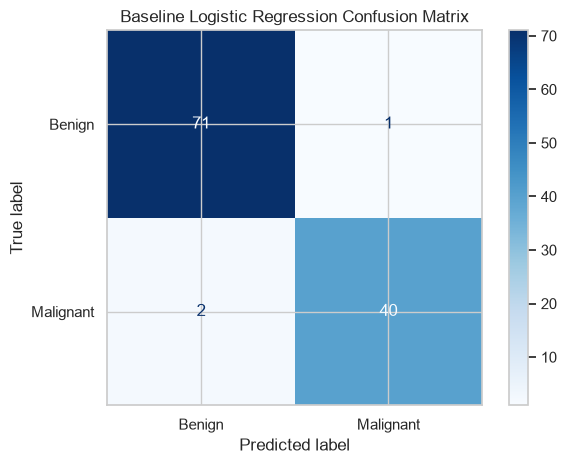

In [16]:

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Benign", "Malignant"],
    cmap="Blues"
)

plt.title("Baseline Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()


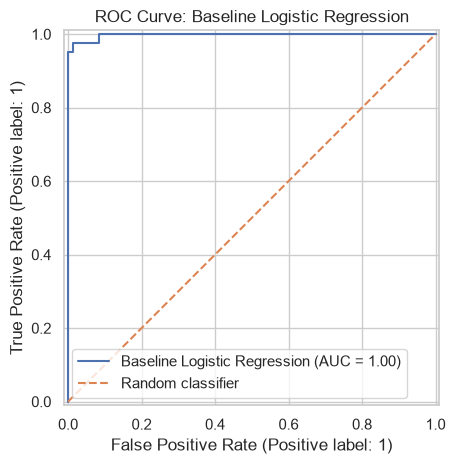

In [17]:

# Visualise how well the model distinguishes between the two classes
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Baseline Logistic Regression"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.title("ROC Curve: Baseline Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()


In [18]:

# Define stratified cross-validation to preserve class proportions
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Create a fresh pipeline for hyperparameter tuning
tuning_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("feature_selection", RFE(
        estimator=LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ),
        n_features_to_select=15
    )),
    ("classifier", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

# Specify the hyperparameters to investigate
param_grid = {
    "feature_selection__n_features_to_select": [10, 15, 20, 25],
    "feature_selection__estimator__C": [0.1, 1.0],
    "classifier__C": [0.01, 0.1, 1.0, 10.0],
    "classifier__class_weight": [None, "balanced"]
}

# Search for the combination that gives the highest cross-validated recall
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True
)

# Fit the tuning process using training data only
grid_search.fit(X_train, y_train)

# Display the best settings and cross-validation result
print("Best hyperparameters:")
print(grid_search.best_params_)

print(
    "\nBest mean cross-validated malignant recall:",
    round(grid_search.best_score_, 4)
)

# Save the best-performing model
improved_model = grid_search.best_estimator_


Best hyperparameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'feature_selection__estimator__C': 0.1, 'feature_selection__n_features_to_select': 20}

Best mean cross-validated malignant recall: 0.9647


IMPROVED MODEL RESULTS
----------------------
Accuracy:  0.9737
Precision: 0.9756
Recall:    0.9524
F1-score:  0.9639
ROC-AUC:   0.9974

Improved model classification report:
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



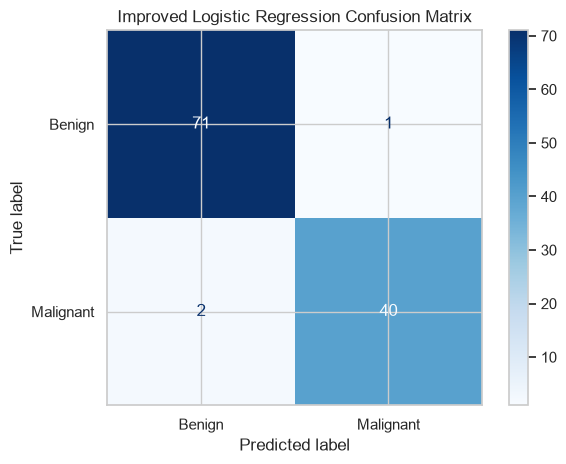

In [19]:

# Predict diagnoses for the same unseen test observations
y_pred_improved = improved_model.predict(X_test)
y_prob_improved = improved_model.predict_proba(X_test)[:, 1]

# Calculate the evaluation metrics
improved_accuracy = accuracy_score(y_test, y_pred_improved)
improved_precision = precision_score(
    y_test, y_pred_improved, zero_division=0
)
improved_recall = recall_score(
    y_test, y_pred_improved, zero_division=0
)
improved_f1 = f1_score(
    y_test, y_pred_improved, zero_division=0
)
improved_auc = roc_auc_score(y_test, y_prob_improved)

print("IMPROVED MODEL RESULTS")
print("----------------------")
print(f"Accuracy:  {improved_accuracy:.4f}")
print(f"Precision: {improved_precision:.4f}")
print(f"Recall:    {improved_recall:.4f}")
print(f"F1-score:  {improved_f1:.4f}")
print(f"ROC-AUC:   {improved_auc:.4f}")

print("\nImproved model classification report:")
print(classification_report(
    y_test,
    y_pred_improved,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

# Plot the improved model's confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_improved,
    labels=[0, 1],
    display_labels=["Benign", "Malignant"],
    cmap="Blues"
)

plt.title("Improved Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()


In [20]:

# Calculate the baseline metrics on the same test set
baseline_accuracy = accuracy_score(y_test, y_pred)
baseline_precision = precision_score(
    y_test, y_pred, zero_division=0
)
baseline_recall = recall_score(
    y_test, y_pred, zero_division=0
)
baseline_f1 = f1_score(
    y_test, y_pred, zero_division=0
)
baseline_auc = roc_auc_score(y_test, y_prob)

# Create a table comparing both models
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Malignant Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Baseline Model": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_auc
    ],
    "Improved Model": [
        improved_accuracy,
        improved_precision,
        improved_recall,
        improved_f1,
        improved_auc
    ]
})

comparison["Change"] = (
    comparison["Improved Model"] - comparison["Baseline Model"]
)

print("Baseline versus improved model:")
display(comparison.round(4))


Baseline versus improved model:


,Metric,Baseline Model,Improved Model,Change
0,Accuracy,0.9737,0.9737,0.0000
1,Precision,0.9756,0.9756,0.0000
2,Malignant Recall,0.9524,0.9524,0.0000
3,F1-score,0.9639,0.9639,0.0000
4,ROC-AUC,0.9977,0.9974,-0.0003


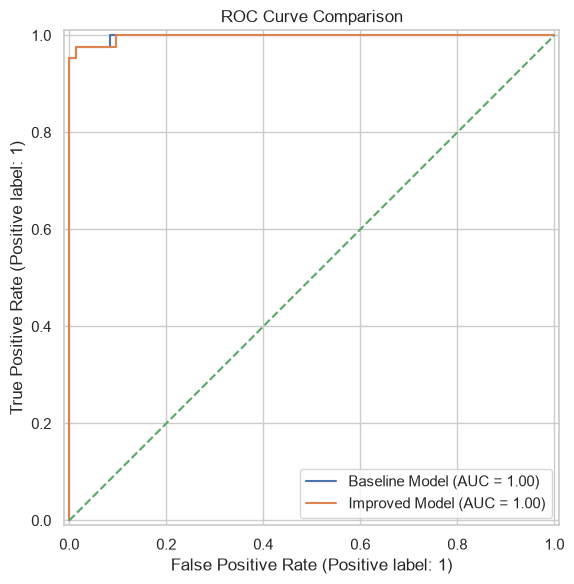

In [21]:

# Compare the discrimination ability of the two models
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Baseline Model",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_improved,
    name="Improved Model",
    ax=ax
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random classifier"
)

ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()
